# Experts por conceito radiológico

**Pergunta:** um nódulo pequeno pode ter um sinal importante que o modelo único não valoriza? Testamos experts separados e usamos a maior pontuação que qualquer um deles dá. Isso pode recuperar positivos, mas também pode aumentar os falsos alarmes.

Só usamos **radiomics de segmentação 3D** e o alvo binário: média dos leitores **>3 é positivo**, **<3 é negativo**. Média igual a 3 fica de fora. São avaliações dos radiologistas, **não diagnósticos confirmados de cancro**.

A população ge3 tem 622 nódulos, dos quais 471 têm alvo binário. Depois de excluir cópias confirmadas de CT, ficam **459 nódulos: 85 positivos e 374 negativos**. Todas as comparações abaixo usam estes mesmos nódulos. LIDC entra apenas no treino.

Este notebook só lê resultados guardados. Para os produzir, na raiz do projeto:

```bash
uv run python -m src.concept_experts --n-jobs 2
```

## 1. O que cada expert lê?

Os sete conceitos são **lobulação, espiculação, esfericidade, margem, textura, calcificação e visibilidade (subtlety)**. Textura aqui é a avaliação visual de sólido/não sólido, não uma matriz radiomics. Calcificação significa que algum leitor assinalou a sua presença, sem ordenar os tipos de calcificação. Estrutura interna não entra porque não está disponível nas anotações LIDC limpas.

Cada expert tem dois passos simples:

1. Uma floresta aprende a **prever o conceito a partir das radiomics**.
2. Uma regressão logística aprende a dar uma pontuação de malignidade usando **só esse conceito previsto**.

As previsões usadas no passo 2 vêm de grupos de pacientes separados: a anotação de um paciente não ajuda a prever o próprio conceito. **No teste não entram anotações reais**, apenas radiomics. O expert de margem, por exemplo, usa a margem prevista, não a margem atribuída pelo leitor.

Há ainda um oitavo expert de **forma medida na máscara**, que usa diretamente as 14 features geométricas. O ensemble usa o **máximo das pontuações dos oito experts**, não a maior nota de 1 a 5. Este máximo é uma pontuação de alerta, não uma probabilidade calibrada.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.auxiliary import CONCEPTS
from src.binary_evaluation import binary_metrics
from src.concept_experts import maximum_positive_score

KEYS = ['LNDbID', 'FindingID']
LABEL = 'target_binary_mean'
folder = ROOT / 'models/segmentation_concept_experts'
metrics = pd.read_csv(folder / 'metrics.csv')
assert metrics.completed_folds.eq(5).all(), 'O treino dos cinco folds ainda não terminou.'
predictions = pd.read_csv(folder / 'validation_predictions.csv')
assert not predictions.duplicated(['model'] + KEYS).any()
names = {
    'lobulation': 'Lobulação', 'spiculation': 'Espiculação',
    'sphericity': 'Esfericidade', 'margin': 'Margem',
    'texture': 'Textura visual', 'calcification': 'Calcificação',
    'subtlety': 'Visibilidade', 'shape': 'Forma da máscara',
    'all_radiomics': 'BRF, todas as radiomics',
    'maximum': 'Máximo dos 8 experts',
    'previous_tuned': 'BRF filtrado + tuning',
}
tables = {name: rows.set_index(KEYS).sort_index()
          for name, rows in predictions.groupby('model', sort=False)}
reference = tables['all_radiomics']
assert len(reference) == 459 and reference[LABEL].sum() == 85
for name, table in tables.items():
    pd.testing.assert_frame_equal(
        table[['fold', 'calibration_fold', LABEL]],
        reference[['fold', 'calibration_fold', LABEL]],
    )
expert_scores = pd.DataFrame({name: tables[name].score for name in CONCEPTS + ['shape']})
np.testing.assert_allclose(tables['maximum'].score, maximum_positive_score(expert_scores))

previous = ROOT / 'models/segmentation_binary_diameter07_tuned/validation_predictions.csv'
if previous.exists():
    saved = pd.read_csv(previous)
    saved = saved[saved.model.eq('Binary Balanced RF, all features')].set_index(KEYS).sort_index()
    pd.testing.assert_frame_equal(
        saved[['fold', 'calibration_fold', LABEL]].astype(int),
        reference[['fold', 'calibration_fold', LABEL]].astype(int),
    )
    saved['diameter_mm'] = reference.diameter_mm
    tables['previous_tuned'] = saved
main = ['all_radiomics'] + (['previous_tuned'] if 'previous_tuned' in tables else []) + ['maximum']

def report(rows):
    result = binary_metrics(rows[LABEL], rows.prediction)
    return {
        'N': result['nodules'], 'positivos': result['TP'] + result['FN'],
        'TP': result['TP'], 'FN': result['FN'], 'FP': result['FP'], 'TN': result['TN'],
        'TPR': result['sensitivity'], 'FPR': 1 - result['specificity'],
        'accuracy': result['accuracy'],
        'AUC': roc_auc_score(rows[LABEL], rows.score) if rows[LABEL].nunique() == 2 else np.nan,
    }

summary = pd.DataFrame({names[name]: report(tables[name]) for name in main}).T


## 2. O máximo ajuda?

Em cada rotação, três folds LNDb e LIDC treinam o modelo. Outro fold escolhe o **maior limiar que mantém todos os positivos desse fold**. O último fold testa o limiar, sem voltar a ajustar o modelo. Cada expert e o máximo têm o seu próprio limiar. **Zero FN na escolha do limiar não garante zero FN no teste.**

A primeira tabela compara o modelo único, a referência anterior com filtro/tuning e o máximo. **TP** são positivos encontrados, **FN** positivos falhados, **FP** falsos alarmes e **TN** negativos rejeitados. **TPR = TP/(TP+FN)** e **FPR = FP/(FP+TN)**. A accuracy conta todos os acertos. A AUC resume a ordenação das pontuações, não este limiar específico. Procuramos menos FN sem aceitar falsos alarmes desnecessários.

In [2]:
display(summary[['TP', 'FN', 'FP', 'TN', 'TPR', 'FPR', 'accuracy', 'AUC']].round(3))
print('A seguir, cada expert sozinho, com o seu próprio limiar escolhido fora do teste:')
individual = pd.DataFrame({names[name]: report(tables[name]) for name in CONCEPTS + ['shape']}).T
display(individual[['TP', 'FN', 'FP', 'TN', 'TPR', 'FPR', 'accuracy', 'AUC']].round(3))


,TP,FN,FP,TN,TPR,FPR,accuracy,AUC
"BRF, todas as radiomics",82.0,3.0,212.0,162.0,0.965,0.567,0.532,0.859
BRF filtrado + tuning,83.0,2.0,196.0,178.0,0.976,0.524,0.569,0.865
Máximo dos 8 experts,82.0,3.0,250.0,124.0,0.965,0.668,0.449,0.827


A seguir, cada expert sozinho, com o seu próprio limiar escolhido fora do teste:


,TP,FN,FP,TN,TPR,FPR,accuracy,AUC
Lobulação,80.0,5.0,219.0,155.0,0.941,0.586,0.512,0.830
Espiculação,79.0,6.0,245.0,129.0,0.929,0.655,0.453,0.807
Esfericidade,80.0,5.0,327.0,47.0,0.941,0.874,0.277,0.628
Margem,78.0,7.0,262.0,112.0,0.918,0.701,0.414,0.705
Textura visual,83.0,2.0,326.0,48.0,0.976,0.872,0.285,0.545
Calcificação,83.0,2.0,302.0,72.0,0.976,0.807,0.338,0.595
Visibilidade,80.0,5.0,337.0,37.0,0.941,0.901,0.255,0.740
Forma da máscara,82.0,3.0,289.0,85.0,0.965,0.773,0.364,0.835


## 3. ROC: sobe pelo eixo Y antes de ir para a direita?

**X = FPR. Y = TPR.** Subir junto ao eixo Y significa encontrar mais positivos sem acrescentar falsos alarmes. No topo, **TPR=1 significa FN=0**. Aí queremos estar o mais à esquerda possível.

As curvas usam as previsões guardadas dos pacientes que ficaram fora do treino. Os círculos assinalam o primeiro ponto com FN=0 **nestas curvas**. Esses pontos são descritivos: usam os rótulos aqui mostrados para escolher o limiar. **Não substituem o teste do limiar separado da secção 2.**

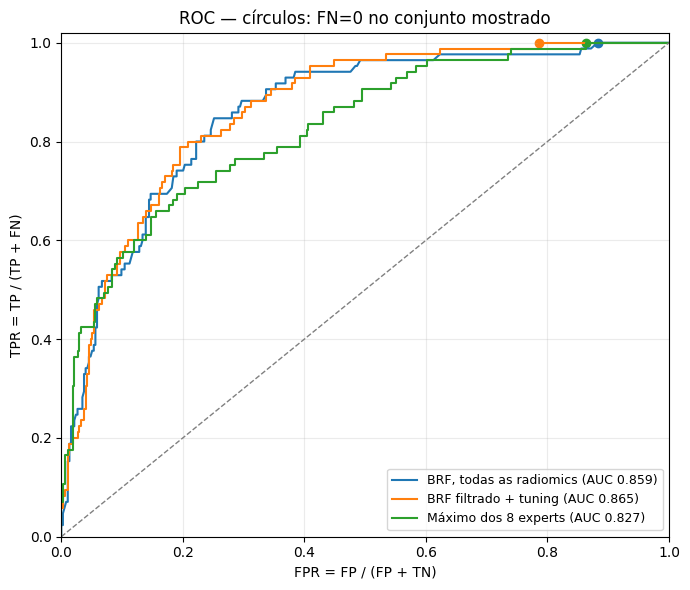

In [3]:
fig, ax = plt.subplots(figsize=(7, 6))
for name in main:
    rows = tables[name]
    fpr, tpr, _ = roc_curve(rows[LABEL], rows.score, drop_intermediate=False)
    line, = ax.plot(fpr, tpr, label=f'{names[name]} (AUC {roc_auc_score(rows[LABEL], rows.score):.3f})')
    first_zero_fn = np.flatnonzero(tpr == 1)[0]
    ax.scatter(fpr[first_zero_fn], 1, color=line.get_color(), marker='o', clip_on=False)
ax.plot([0, 1], [0, 1], '--', color='grey', linewidth=1)
ax.set(xlabel='FPR = FP / (FP + TN)', ylabel='TPR = TP / (TP + FN)',
       xlim=(0, 1), ylim=(0, 1.02), title='ROC — círculos: FN=0 no conjunto mostrado')
ax.grid(alpha=0.25)
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()


## 4. E nos nódulos pequenos?

Aqui **pequeno significa diâmetro equivalente ≤6 mm**, calculado a partir do volume da máscara. É um corte fixo para descrever resultados, não um parâmetro escolhido para melhorar o modelo. Usamos os mesmos limiares da secção 2, sem os voltar a escolher para os pequenos.

A tabela separa os pequenos dos restantes. Mostra quantos positivos existem em cada grupo, quantos são encontrados e quantos são falhados, além dos falsos alarmes. Depois listamos os positivos pequenos falhados pela referência anterior e encontrados pelo máximo. O expert indicado é o que deu a maior pontuação, **não uma causa demonstrada da avaliação do nódulo**.

In [4]:
small_rows = []
for name in main:
    table = tables[name]
    for group, mask in [('≤6 mm', table.diameter_mm.le(6)), ('>6 mm', table.diameter_mm.gt(6))]:
        small_rows.append({'modelo': names[name], 'diâmetro': group, **report(table.loc[mask])})
small_results = pd.DataFrame(small_rows).set_index(['modelo', 'diâmetro'])
display(small_results[['N', 'positivos', 'TP', 'FN', 'FP', 'TN', 'TPR', 'FPR', 'accuracy']].round(3))

reference_name = 'previous_tuned' if 'previous_tuned' in tables else 'all_radiomics'
base, maximum = tables[reference_name], tables['maximum']
small_positive = base.diameter_mm.le(6) & base[LABEL].eq(1)
recovered = small_positive & base.prediction.eq(0) & maximum.prediction.eq(1)
lost = small_positive & base.prediction.eq(1) & maximum.prediction.eq(0)
print(f'Pequenos positivos recuperados pelo máximo: {int(recovered.sum())}')
print(f'Pequenos positivos que a referência encontrava mas o máximo falha: {int(lost.sum())}')
if recovered.any():
    found = maximum.loc[recovered, ['diameter_mm', 'winning_expert']].copy()
    found['winning_expert'] = found.winning_expert.map(names)
    display(found.rename(columns={'diameter_mm': 'diâmetro (mm)',
                                  'winning_expert': 'expert com maior pontuação'}).round(2))


N  positivos  TP  FN   FP   TN    TPR  \
modelo                  diâmetro                                            
BRF, todas as radiomics ≤6 mm     309         21  18   3  141  147  0.857   
                        >6 mm     150         64  64   0   71   15  1.000   
BRF filtrado + tuning   ≤6 mm     309         21  19   2  127  161  0.905   
                        >6 mm     150         64  64   0   69   17  1.000   
Máximo dos 8 experts    ≤6 mm     309         21  19   2  167  121  0.905   
                        >6 mm     150         64  63   1   83    3  0.984   

                                    FPR  accuracy  
modelo                  diâmetro                   
BRF, todas as radiomics ≤6 mm     0.490     0.534  
                        >6 mm     0.826     0.527  
BRF filtrado + tuning   ≤6 mm     0.441     0.583  
                        >6 mm     0.802     0.540  
Máximo dos 8 experts    ≤6 mm     0.580     0.453  
                        >6 mm     0.965     0.440

Pequenos positivos recuperados pelo máximo: 0
Pequenos positivos que a referência encontrava mas o máximo falha: 0


## 5. O que aproveitar?

Comparamos o máximo com a melhor referência anterior disponível, nos mesmos pacientes. Menos FN interessa, mas não escondemos os FP adicionais nem os positivos que deixam de ser encontrados. O máximo não é automaticamente melhor: um expert que dá pontuações altas a muitos negativos pode piorá-lo.

In [5]:
base_result, max_result = report(base), report(maximum)
print(f"Referência ({names[reference_name]}): FN={base_result['FN']}, FP={base_result['FP']}, "
      f"accuracy={base_result['accuracy']:.1%}")
print(f"Máximo: FN={max_result['FN']}, FP={max_result['FP']}, accuracy={max_result['accuracy']:.1%}")
if max_result['FN'] < base_result['FN']:
    print('O máximo reduz os FN nesta comparação. Verificar o custo em falsos alarmes.')
elif max_result['FN'] == base_result['FN']:
    print('O máximo não reduz os FN. Com os FN empatados, preferir menos FP.')
else:
    print('O máximo falha mais positivos. Não melhora o objetivo principal nesta comparação.')
print('Zero FN no teste.' if max_result['FN'] == 0 else 'O máximo ainda não atinge zero FN no teste.')
print('Estes são resultados exploratórios no LNDb, não uma garantia para novos pacientes.')


Referência (BRF filtrado + tuning): FN=2, FP=196, accuracy=56.9%
Máximo: FN=3, FP=250, accuracy=44.9%
O máximo falha mais positivos. Não melhora o objetivo principal nesta comparação.
O máximo ainda não atinge zero FN no teste.
Estes são resultados exploratórios no LNDb, não uma garantia para novos pacientes.


## 6. O modelo reconhece os conceitos anotados?

Comparamos anotações e previsões nos mesmos pacientes fora do treino, no total e por tamanho. **Erro médio absoluto (MAE): menor é melhor. Spearman: maior indica melhor ordenação dos ratings.** Para calcificação usamos AUC, porque o alvo é presença/ausência. Os outros seis conceitos usam a escala 1–5, por isso os seus erros não devem ser comparados diretamente com o erro de calcificação, na escala 0–1. A forma geométrica não tem uma anotação equivalente para esta comparação.

Esta tabela mede a recuperação dos conceitos, não a previsão de malignidade. Os modelos e os limiares ficam fixos.

In [6]:
from src.auxiliary import load_concepts
from src.radiomics_extraction import load_paths

ensemble = tables['maximum']
annotations = load_concepts(
    ensemble.reset_index()[KEYS], 'lndb', load_paths()
).set_index(KEYS).reindex(ensemble.index)
estimated = predictions[predictions.model.isin(CONCEPTS)].pivot(
    index=KEYS, columns='model', values='concept_prediction'
).reindex(ensemble.index)
groups = {
    'Todos': ensemble.diameter_mm.notna(),
    '≤6 mm': ensemble.diameter_mm.le(6),
    '>6 mm': ensemble.diameter_mm.gt(6),
}
rows = []
for concept in CONCEPTS:
    for group, mask in groups.items():
        valid = mask & annotations[concept].notna() & estimated[concept].notna()
        a, b = annotations.loc[valid, concept], estimated.loc[valid, concept]
        if a.empty:
            continue
        calcification = concept == 'calcification'
        rows.append({
            'conceito': names[concept], 'grupo': group, 'N': len(a),
            'MAE': (a - b).abs().mean(),
            'Spearman': a.corr(b, method='spearman')
                if not calcification and a.nunique() > 1 and b.nunique() > 1 else np.nan,
            'AUC': roc_auc_score(a, b)
                if calcification and a.nunique() == 2 else np.nan,
        })
concept_results = pd.DataFrame(rows).set_index(['conceito', 'grupo'])
display(concept_results.round(3))


N    MAE  Spearman    AUC
conceito       grupo                             
Lobulação      Todos  459  0.496     0.428    NaN
               ≤6 mm  309  0.411     0.231    NaN
               >6 mm  150  0.670     0.422    NaN
Espiculação    Todos  459  0.453     0.375    NaN
               ≤6 mm  309  0.321     0.191    NaN
               >6 mm  150  0.725     0.338    NaN
Esfericidade   Todos  459  0.856     0.467    NaN
               ≤6 mm  309  0.869     0.440    NaN
               >6 mm  150  0.829     0.523    NaN
Margem         Todos  459  0.579     0.457    NaN
               ≤6 mm  309  0.541     0.429    NaN
               >6 mm  150  0.658     0.490    NaN
Textura visual Todos  459  0.394     0.528    NaN
               ≤6 mm  309  0.405     0.519    NaN
               >6 mm  150  0.374     0.537    NaN
Calcificação   Todos  459  0.172       NaN  0.894
               ≤6 mm  309  0.163       NaN  0.884
               >6 mm  150  0.190       NaN  0.911
Visibilidade   Todos  459  0.729     0.556    NaN
               ≤6 mm  309  0.809     0.420    NaN
               >6 mm  150  0.565     0.526    NaN

## 7. Que features influenciam cada expert?

O painel mostra as cinco features com maior **SHAP médio absoluto**, calculado nos pacientes fora do treino de cada fold. Nos sete conceitos, SHAP explica o **conceito previsto**. No expert de forma, explica a **pontuação binária**. As escalas são diferentes e não devem ser somadas nem comparadas entre experts.

Usamos as árvores guardadas, sem novo treino, e a distribuição dos caminhos de treino como referência (`tree_path_dependent`). Features correlacionadas podem partilhar a influência. SHAP explica previsões, **não demonstra causas dos erros nem elimina o efeito do tamanho**.

Documentação: [TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html), [Explanation](https://shap.readthedocs.io/en/latest/generated/shap.Explanation.html) e [waterfall](https://shap.readthedocs.io/en/latest/generated/shap.plots.waterfall.html).

/home/jp/Documents/por-definir-ds/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fold 1 explicado


Fold 2 explicado


Fold 3 explicado


Fold 4 explicado


Fold 5 explicado


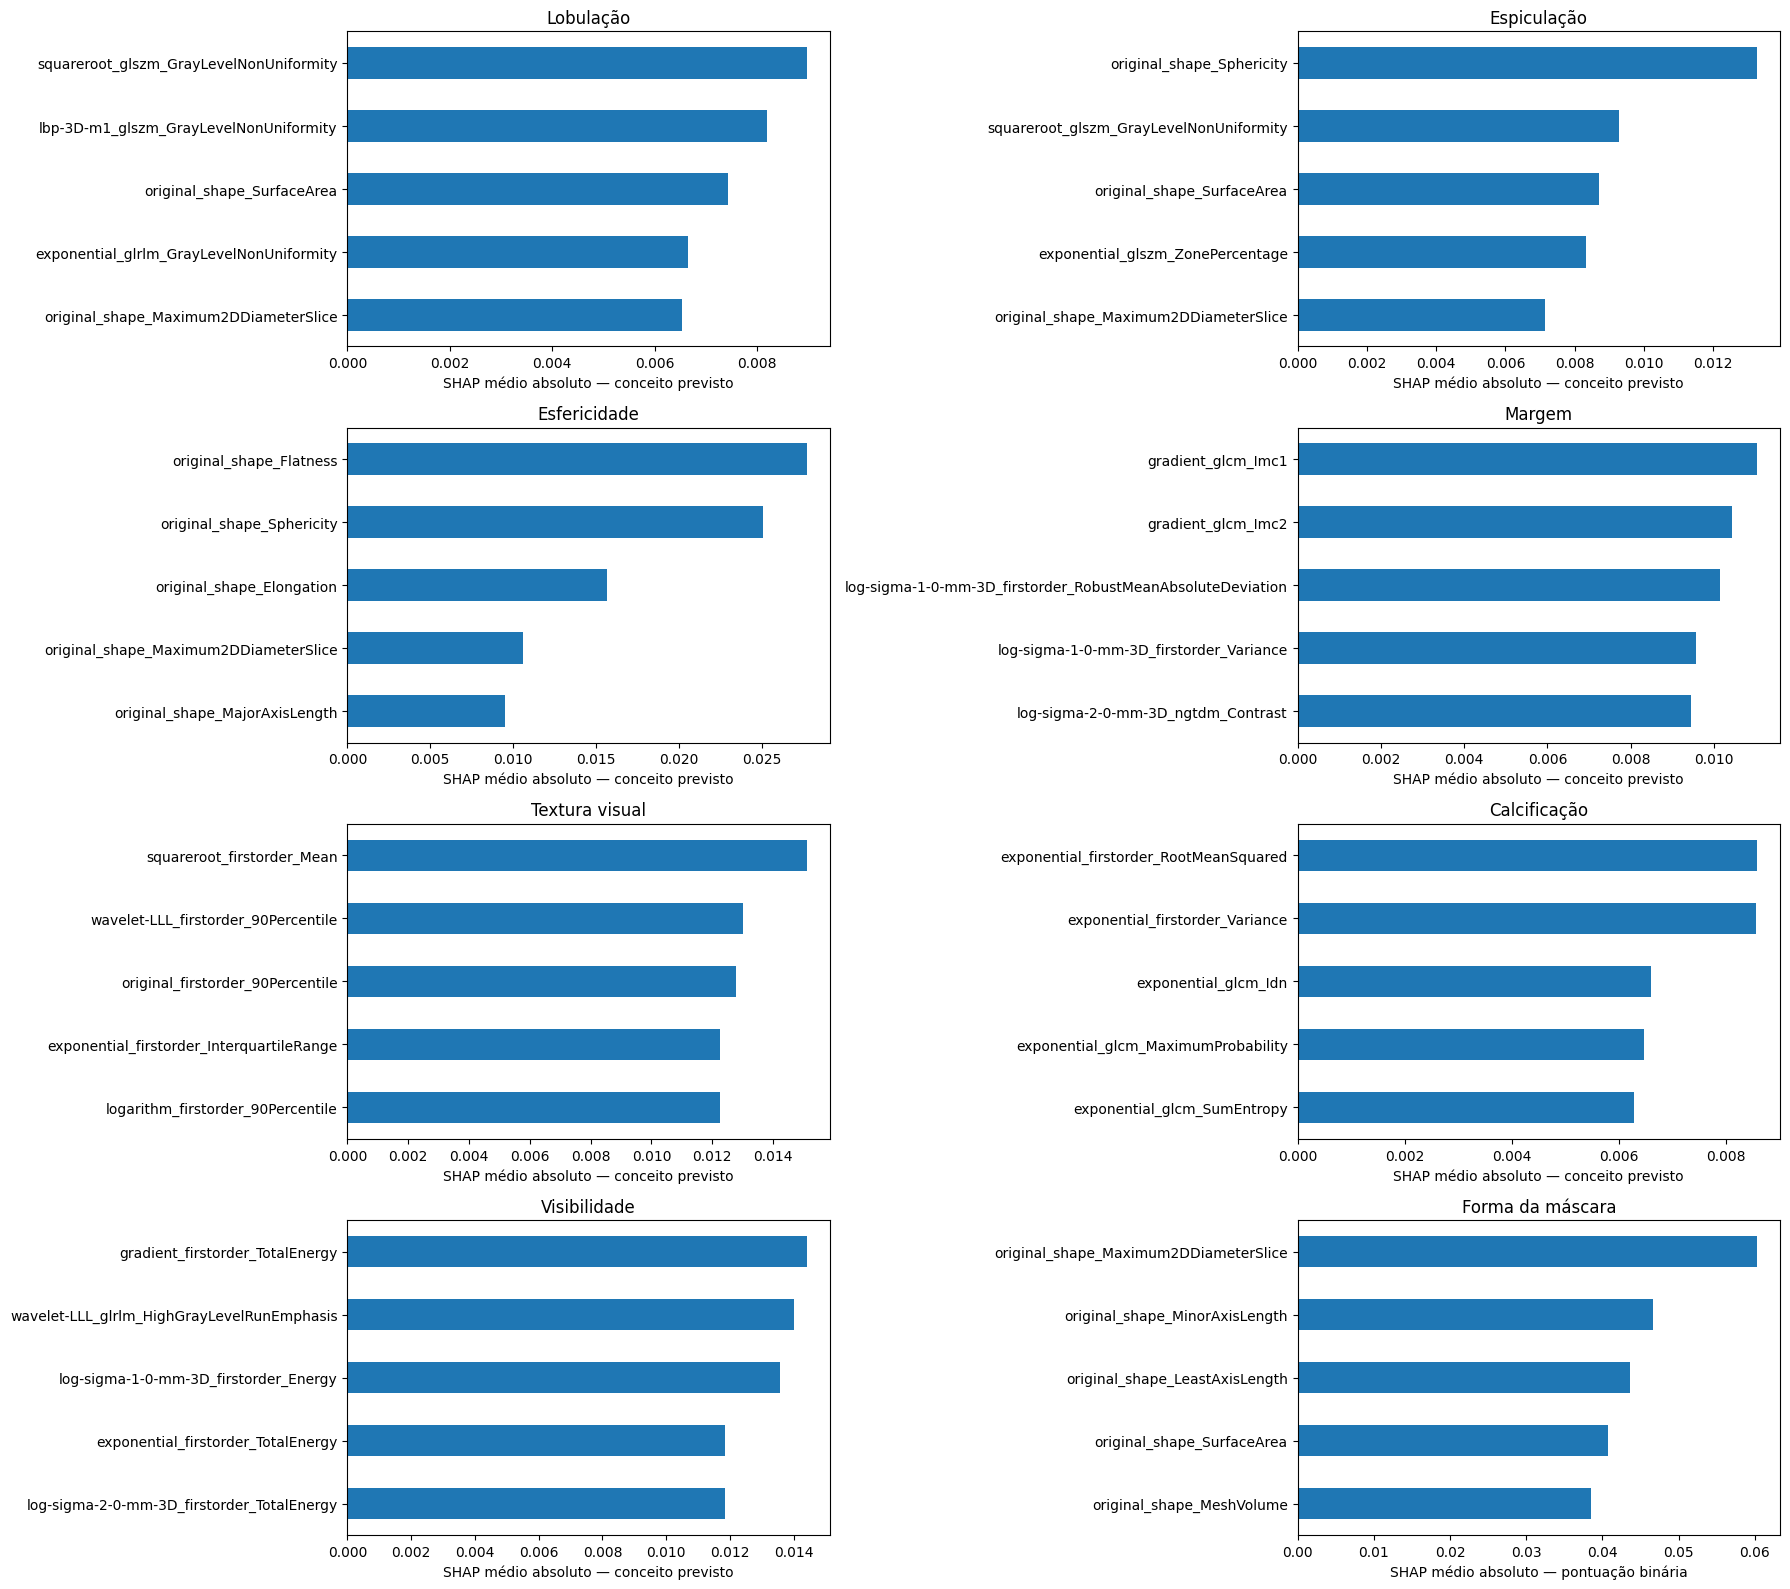

In [7]:
import __main__
import joblib
import shap
from threadpoolctl import threadpool_limits
from src.concept_experts import ConceptExpert

# Compatibilidade com os modelos guardados pela versão inicial do CLI.
__main__.ConceptExpert = ConceptExpert

features = pd.read_csv(
    ROOT / 'data/lndb_ge3_segmentation_3d_c50_hu.csv'
).set_index(KEYS).replace([np.inf, -np.inf], np.nan)
assert features.index.is_unique
experts = CONCEPTS + ['shape']
explanations = {name: [] for name in experts}

with threadpool_limits(limits=2):
    for fold, patients in ensemble.groupby('fold'):
        saved = joblib.load(folder / f'fold_{int(fold)}.joblib')
        assert saved['test_fold'] == int(fold)
        for name in experts:
            bundle = saved['models'][name]
            model, columns = bundle['model'], bundle['features']
            pipe = model.regressor_ if name in CONCEPTS else model
            x = features.loc[patients.index, columns]
            if name in CONCEPTS:
                x = x.to_numpy()
            x = pipe[:-1].transform(x)
            explanation = shap.TreeExplainer(
                pipe[-1], feature_perturbation='tree_path_dependent'
            )(x)
            if explanation.values.ndim == 3:
                positive = list(pipe[-1].classes_).index(1)
                explanation = explanation[:, :, positive]
            explanation = shap.Explanation(
                values=explanation.values, base_values=explanation.base_values,
                data=x, feature_names=columns,
            )
            output = 'concept_prediction' if name in CONCEPTS else 'score'
            np.testing.assert_allclose(
                explanation.base_values + explanation.values.sum(axis=1),
                tables[name].loc[patients.index, output], rtol=1e-5, atol=1e-6,
            )
            explanations[name].append((patients.index, explanation))
        print(f'Fold {int(fold)} explicado')

fig, axes = plt.subplots(4, 2, figsize=(18, 16))
for name, ax in zip(experts, axes.flat):
    values = pd.concat([
        pd.DataFrame(e.values, index=index, columns=e.feature_names)
        for index, e in explanations[name]
    ])
    importance = values.abs().mean().nlargest(5).sort_values()
    importance.plot.barh(ax=ax)
    ax.set_title(names[name])
    unit = 'conceito previsto' if name in CONCEPTS else 'pontuação binária'
    ax.set_xlabel(f'SHAP médio absoluto — {unit}')
plt.tight_layout()
plt.show()


## 8. Como chegou a erros concretos?

A primeira tabela mostra os três falsos negativos do ensemble e, para cada um, um positivo encontrado com o diâmetro mais próximo, sem repetir casos. É uma comparação descritiva, não um controlo de todas as diferenças entre nódulos.

A segunda tabela abre um caso: anotações, conceitos previstos e pontuações dos oito experts. A forma não tem um conceito anotado ou previsto, apenas uma pontuação binária. Comparamos o máximo com o seu limiar guardado. **Não alteramos o limiar nem usamos a anotação real para produzir a previsão.**

O waterfall explica o expert escolhido: vermelho aumenta e azul reduz a sua previsão relativamente ao valor de referência. Começamos na espiculação do nódulo LNDb 53/2. As variáveis `case` e `expert` permitem explorar os outros casos e componentes. O gráfico explica essa previsão, não a distância até à anotação do leitor nem o ensemble inteiro.

,,diameter_mm,prediction,score,threshold,winning_expert,resultado
LNDbID,FindingID,,,,,,
53,2,4.040,0,0.548,0.591,Calcificação,FN
119,1,5.183,0,0.547,0.574,Esfericidade,FN
161,4,6.202,0,0.508,0.565,Visibilidade,FN
248,2,4.139,1,0.691,0.591,Esfericidade,TP
200,2,5.183,1,0.629,0.586,Esfericidade,TP
18,5,6.225,1,0.771,0.565,Esfericidade,TP


,conceito anotado,conceito previsto,pontuação binária
Calcificação,0.0,0.080,0.548
Lobulação,3.0,1.229,0.125
Margem,2.5,4.352,0.385
Forma da máscara,NaN,NaN,0.120
Esfericidade,5.0,3.698,0.516
Espiculação,4.0,1.136,0.133
Visibilidade,5.0,3.724,0.454
Textura visual,5.0,4.591,0.489


Máximo: 0.548 | Limiar: 0.591


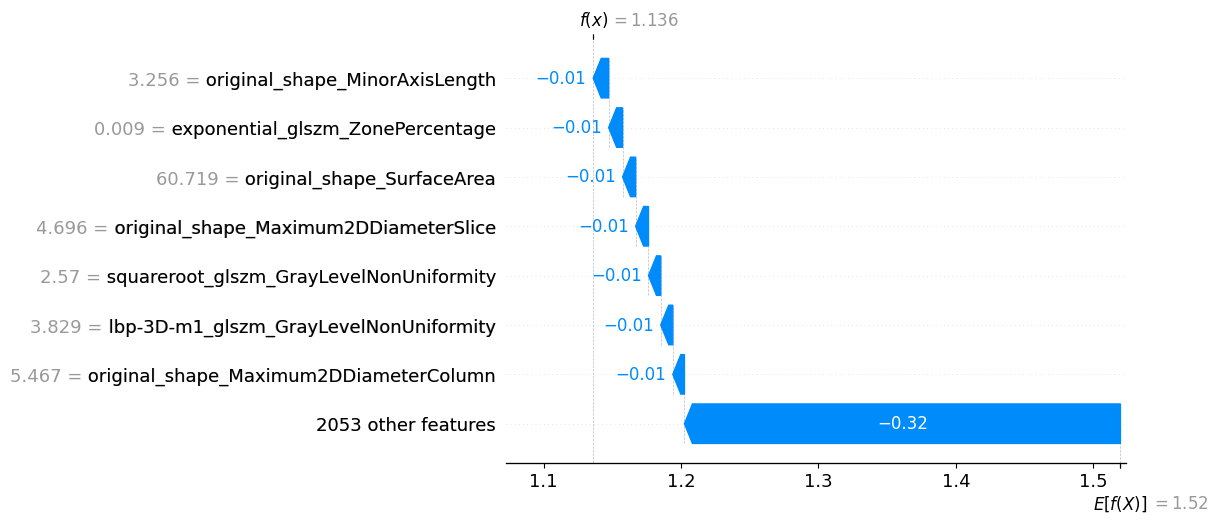

In [8]:
failed = ensemble[ensemble[LABEL].eq(1) & ensemble.prediction.eq(0)]
detected = ensemble[ensemble[LABEL].eq(1) & ensemble.prediction.eq(1)].copy()
cases = list(failed.index)
for _, patient in failed.iterrows():
    if detected.empty:
        break
    nearest = (detected.diameter_mm - patient.diameter_mm).abs().idxmin()
    cases.append(nearest)
    detected = detected.drop(index=[nearest])
comparison = ensemble.loc[
    cases, ['diameter_mm', 'prediction', 'score', 'threshold', 'winning_expert']
].copy()
comparison['resultado'] = np.where(comparison.prediction.eq(0), 'FN', 'TP')
comparison['winning_expert'] = comparison.winning_expert.map(names)
display(comparison.round(3))

case = (53, 2)
expert = 'spiculation'  # Qualquer CONCEPTS ou 'shape'.
detail = pd.DataFrame({
    'conceito anotado': annotations.loc[case],
    'conceito previsto': estimated.loc[case],
    'pontuação binária': pd.Series({
        name: tables[name].loc[case, 'score'] for name in experts
    }),
})
display(detail.rename(index=names).round(3))
patient = ensemble.loc[case]
print(f'Máximo: {patient.score:.3f} | Limiar: {patient.threshold:.3f}')
index, explanation = next(
    (index, e) for index, e in explanations[expert] if case in index
)
shap.plots.waterfall(explanation[index.get_loc(case)], max_display=8)
